# Uncertainty Estimation Practical — Part II
This notebook is self-contained and uses the same spiral data construction as Part I. Complete the three marked implementation tasks, then answer the discussion questions.

**Running in Google Colab.** Open the `.ipynb` using **File > Upload notebook**, connect to a Python runtime, and run cells in order. A CPU runtime is sufficient for the core exercises. Use the runtime's existing `jax`, `numpy`, and `matplotlib`; no toy-data download is needed. If an import reports a missing package, run `%pip install jax numpy matplotlib` in a setup cell before the imports, then restart the runtime. For local Jupyter, follow `README.md`. After changing a training setting, restart the runtime/kernel and run all cells again: JAX-compiled functions may otherwise retain previously captured optimizer settings. Training settings remain at the start of each training cell.

**Note.** for this year an LLM has been used to polish this course exercise. Please report to the teachers if you encounter an issue with the notebook.


## Training Independent Subnetworks for Robust Prediction — Havasi et al. (2021)

### Motivation
A [deep ensemble](https://arxiv.org/abs/1612.01474) trains and stores several networks. This can increase training cost, inference computation, and memory use. Distillation can reduce deployment cost after training an ensemble. Weight-sharing methods instead aim to obtain multiple predictions within a more compact model.

Here we study [multi-input multi-output (MIMO) networks](https://arxiv.org/abs/2010.06610). A shared hidden network receives $M$ input slots and produces $M$ output heads. The first and final layers grow with $M$, while hidden-layer widths remain unchanged. Thus this is a computational trade-off, not literally a zero-cost ensemble; do not assume that its heads are statistically independent simply because they are called subnetworks.

### Original paper's abstract (2021)
The following reports the paper's results, not a guarantee for this toy network.

"
Recent approaches to efficiently ensemble neural networks have shown that strong robustness and uncertainty performance can be achieved with a negligible gain in parameters over the original network. However, these methods still require multiple forward passes for prediction, leading to a significant computational cost. In this work, we show a surprising result: the benefits of using multiple predictions can be achieved `for free' under a single model's forward pass. In particular, we show that, using a multi-input multi-output (MIMO) configuration, one can utilize a single model's capacity to train multiple subnetworks that independently learn the task at hand. By ensembling the predictions made by the subnetworks, we improve model robustness without increasing compute. We observe a significant improvement in negative log-likelihood, accuracy, and calibration error on CIFAR10, CIFAR100, ImageNet, and their out-of-distribution variants compared to previous methods.
"

### Method
The shape flow below replaces the externally hosted illustration so that the instructions remain available offline:

```text
Training tuple:  (x_1, ..., x_M), generally different examples
Flatten inputs:  M × D → shared hidden layers → M × K logits
Targets:         (y_1, ..., y_M), aligned with their input slots

Inference tuple: (x, ..., x), the SAME example in every slot
Prediction:      average the M heads' class probabilities
```

For training, independently permute the batch for each head, using a different PRNG subkey. Apply each head's permutation to **both inputs and targets**. Reusing one common permutation would make every head see the same example in each tuple and would not implement this construction.

At evaluation, repeat each input across all slots. Do not shuffle the input, and do not average logits. Note that training uses mixed tuples whereas evaluation uses repeated inputs; this is a deliberate feature of the basic MIMO method studied here.

### Implementation tasks
1. **Architecture:** expand the input and output layer sizes to $MD$ and $MK$, keeping hidden widths at 150.
2. **Training loss:** construct the independently shuffled inputs/targets and average categorical cross-entropy over the $MN$ head-example pairs. Sum over classes. Add the same $\lambda\|\theta\|_2$ penalty as in Part I, **once**, after averaging the NLL. This explicit normalization fixes the meaning of `wd`; summing instead of averaging over heads would change the relative strength of the penalty.
3. **Evaluation:** duplicate inputs to shape $(M,N,D)$, evaluate the network, and return the mean and individual head probabilities.

## Classification on [toy dataset] using MIMO :
[toy dataset]: https://cs231n.github.io/neural-networks-case-study/

In [10]:
# Start in a fresh runtime; no %reset magic is needed.
# Colab: use the existing JAX, NumPy, and Matplotlib.
# Only if an import reports a missing package, install it before importing:
# %pip install jax numpy matplotlib
# Then restart the runtime. For local Jupyter setup, see README.md.

In [11]:
import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, random
from jax.scipy.special import logsumexp
from jax.example_libraries import optimizers
from jax import config
from functools import partial
import matplotlib.pyplot as plt
import numpy as np
import time

# For debugging, set True before running the notebook from a fresh kernel.
# jax_debug_nans can also help locate non-finite computations.
config.update("jax_disable_jit", False)
print("JAX:", jax.__version__, "| Devices:", jax.devices())

JAX: 0.12.0 | Devices: [CpuDevice(id=0)]


In [12]:
def one_hot(x, k, dtype=jnp.float32):
    """One-hot encode integer class labels."""
    return jnp.asarray(x[:, None] == jnp.arange(k), dtype)

def generate_datasets(N, K, noise, seed=0):
    """N points per class in a two-dimensional spiral; local, reproducible RNG."""
    rng = np.random.RandomState(seed)
    X = np.zeros((N * K, 2), dtype=np.float32)
    y = np.zeros(N * K, dtype=np.int32)
    for j in range(K):
        ix = slice(N * j, N * (j + 1))
        r = np.linspace(0.0, 1.0, N)
        t = np.linspace(j * 8, (j + 1) * 8, N) + rng.randn(N) * noise * (r + 1.0)
        X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[ix] = j
    X, y = jnp.asarray(X), jnp.asarray(y)
    return X, y, one_hot(y, K)

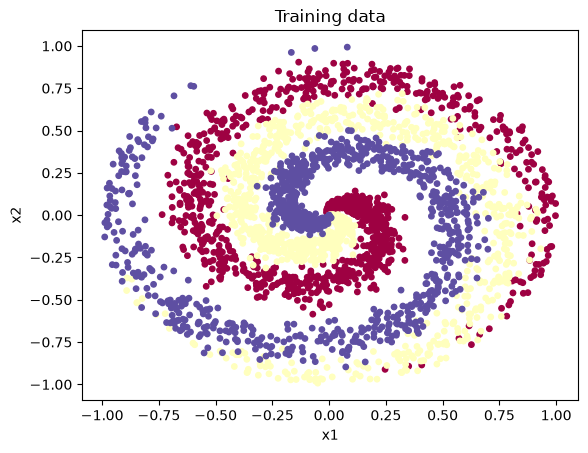

Training: (3000, 2) (3000,) | Held-out: (3000, 2) (3000,)


In [13]:
N = 1000  # points per class
D = 2
K = 3
X, y, y_onehot = generate_datasets(N, K, noise=0.3, seed=0)
# Independent noise realization on the same radial grid; never used for training.
X_test, y_test, y_test_onehot = generate_datasets(N, K, noise=0.3, seed=1)
plt.figure()
plt.scatter(X[:, 0], X[:, 1], c=y, s=15, cmap=plt.cm.Spectral)
plt.title("Training data")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()
print("Training:", X.shape, y.shape, "| Held-out:", X_test.shape, y_test.shape)

In [14]:
# A helper function to randomly initialize weights and biases
# for a dense neural network layer
def random_layer_params(m, n, key, scale=1e-1):
    w_key, b_key = random.split(key)
    return scale * random.normal(w_key, (n, m)), scale * random.normal(b_key, (n,))

# Initialize all layers for a fully-connected neural network with sizes "sizes"
def init_network_params(sizes, key):
    keys = random.split(key, len(sizes))
    return [random_layer_params(m, n, k) for m, n, k in zip(sizes[:-1], sizes[1:], keys)]

def predict_MIMO(params, input):
    """
    The input is of shape (#nets, #examples, #input_dims)=(M,N,D).
    while the two outputs are of shape (#nets, #examples, #classes)=(M,N,K).
    """
    def _predict(params, input):
        M,D = input.shape
        input = input.reshape(M*D)
        activations = input
        for w, b in params[:-1]:
            outputs = jnp.dot(w, activations) + b
            activations = jax.nn.relu(outputs)

        final_w, final_b = params[-1]
        logits = jnp.dot(final_w, activations) + final_b
        logits = logits.reshape(M,-1)
        probs = jax.nn.softmax(logits, axis=1)
        return logits, probs

    logits, probs = vmap(_predict, in_axes=(None, 1))(params, input)
    logits, probs = jnp.transpose(logits, [1, 0, 2]), jnp.transpose(probs, [1, 0, 2])

    return logits, probs

@partial(jit, static_argnums=2)
def evalMIMO(params, inputs, M):
    """TODO: Repeat inputs (N,D) across slots to form (M,N,D), then predict.

    Return mean probabilities (N,K) and all head probabilities (M,N,K).
    Average probabilities over axis 0, not logits and not the class axis.
    """
    repeated = jnp.broadcast_to(inputs, (M,) + inputs.shape)
    _, probs = predict_MIMO(params, repeated)
    return probs.mean(axis=0), probs

def batched_logsumexp(logits):
    """Logits (M,N,K) -> normalization constants (M,N)."""
    return logsumexp(logits, axis=-1)

def lossMIMO(params, inputs, targets, M, wd, seed):
    """TODO: Independently shuffle each head's inputs AND corresponding targets.

    inputs (N,D), one-hot targets (N,K). Split the PRNG key into M subkeys;
    create one permutation per head and use it for both arrays. The batched
    shapes become (M,N,D) and (M,N,K). Sum CE over K, average over M and N,
    and add wd * optimizers.l2_norm(params) once. Return one scalar.
    """
    N = inputs.shape[0]
    keys = random.split(seed, M)
    perms = vmap(lambda key: random.permutation(key, N))(keys)  # (M, N), one permutation per head
    inputs_shuffled = inputs[perms]    # (M, N, D)
    targets_shuffled = targets[perms]  # (M, N, K)
    logits, _ = predict_MIMO(params, inputs_shuffled)
    log_probs = logits - batched_logsumexp(logits)[..., None]
    nll = -jnp.mean(jnp.sum(targets_shuffled * log_probs, axis=-1))
    return nll + wd * optimizers.l2_norm(params)

@partial(jit, static_argnames=("M", "opt_update", "get_params"))
def update_mimo(step, params, x, y, opt_state, M, wd, seed, opt_update, get_params):
    grads = grad(lossMIMO)(params, x, y, M, wd, seed)
    opt_state = opt_update(step, grads, opt_state)
    return get_params(opt_state), opt_state

@partial(jit, static_argnums=2)
def mimo_log_probabilities(params, inputs, M):
    """Stable log of the averaged head probabilities, for NLL reporting only."""
    repeated = jnp.broadcast_to(inputs, (M,) + inputs.shape)
    logits, _ = predict_MIMO(params, repeated)
    return logsumexp(jax.nn.log_softmax(logits, axis=-1), axis=0) - jnp.log(M)

def logging(params_mimo, X, y, M, log_acc_train, log_nll_train):
    # Exercise evalMIMO in evaluation, but compute NLL stably from logits.
    mean, _ = evalMIMO(params_mimo, X, M)
    log_probs = mimo_log_probabilities(params_mimo, X, M)
    log_acc_train.append(float(jnp.mean(jnp.argmax(mean, axis=-1) == y)))
    log_nll_train.append(float(-jnp.mean(log_probs[jnp.arange(len(y)), y])))

In [15]:
# MIMO settings. Retrain from scratch whenever M changes.
M = 8
num_epochs = 2000
step_size = 0.1
wd = 1e-3  # coefficient of the same L2-NORM penalty as Part I

assert M >= 1 and num_epochs >= 1
# TODO: Expand the first and last layers for M input/output slots.
layer_sizes = [D * M, 150, 150, K * M]
assert layer_sizes[0] == D * M and layer_sizes[-1] == K * M

log_acc, log_nll = [], []
opt_init, opt_update, get_params = optimizers.adam(step_size)
params_mimo = init_network_params(layer_sizes, random.PRNGKey(0))
opt_state = opt_init(params_mimo)
key = random.PRNGKey(1)  # stream for training tuples, separate from initialization
start_time = time.perf_counter()
for epoch in range(num_epochs):
    key, seed = random.split(key)
    params_mimo, opt_state = update_mimo(
        epoch, params_mimo, X, y_onehot, opt_state, M, wd, seed, opt_update, get_params)
    logging(params_mimo, X, y, M, log_acc, log_nll)
    if epoch == 0 or (epoch + 1) % 200 == 0 or epoch + 1 == num_epochs:
        print(f"Epoch {epoch+1}: train accuracy {log_acc[-1]:.4f}; train NLL {log_nll[-1]:.4f}")
assert np.isfinite(log_nll).all(), "Non-finite MIMO NLL."
mimo_seconds = time.perf_counter() - start_time
heldout_acc, heldout_nll = [], []
logging(params_mimo, X_test, y_test, M, heldout_acc, heldout_nll)
print(f"Held-out accuracy {heldout_acc[-1]:.4f}; held-out NLL {heldout_nll[-1]:.4f}")
print(f"Training time: {mimo_seconds:.2f} s; parameters: {sum(p.size for p in jax.tree_util.tree_leaves(params_mimo)):,}")

Epoch 1: train accuracy 0.3333; train NLL 1.7078
Epoch 200: train accuracy 0.7820; train NLL 0.7918
Epoch 400: train accuracy 0.8050; train NLL 0.6609
Epoch 600: train accuracy 0.8860; train NLL 0.5945
Epoch 800: train accuracy 0.8897; train NLL 0.5996
Epoch 1000: train accuracy 0.9047; train NLL 0.5379
Epoch 1200: train accuracy 0.9073; train NLL 0.5177
Epoch 1400: train accuracy 0.9110; train NLL 0.5684
Epoch 1600: train accuracy 0.9053; train NLL 0.6579
Epoch 1800: train accuracy 0.9217; train NLL 0.6242
Epoch 2000: train accuracy 0.9140; train NLL 0.6334
Held-out accuracy 0.9057; held-out NLL 0.6438
Training time: 22.80 s; parameters: 28,824


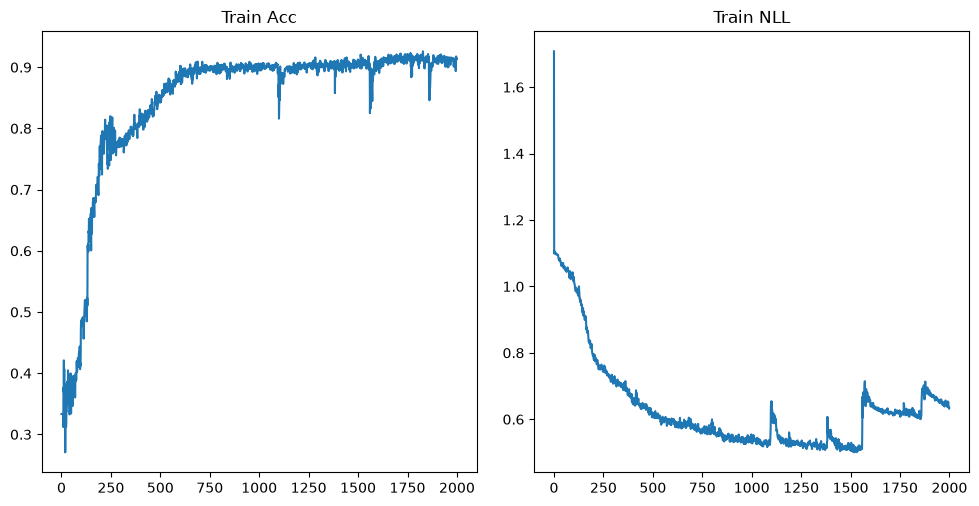

In [16]:
fig, axes = plt.subplots(1,2, figsize=(10,5))
fig.tight_layout()
axes[0].plot(log_acc)
axes[1].plot(log_nll)
axes[0].title.set_text('Train Acc')
axes[1].title.set_text('Train NLL')

In [17]:
def entropy(preds):
    """Categorical entropy in nats along the final axis; exactly 0*log(0)=0."""
    preds = np.asarray(preds, dtype=np.float64)
    safe = np.where(preds > 0, preds, 1.0)
    return -np.sum(preds * np.log(safe), axis=-1)

def js_terms(distributions):
    """Input (M, N, K); return total and average member entropy, each (N,)."""
    distributions = np.asarray(distributions)
    return entropy(distributions.mean(axis=0)), entropy(distributions).mean(axis=0)

def visualize_predictions(X, y, params_list, min=-2.0, max=2.0, res=200, num_nets=1):
    xs = np.linspace(min, max, res)
    ys = np.linspace(min, max, res)
    xy = np.asarray([(_x, _y) for _x in xs for _y in ys], dtype=np.float32)
    predictions_ensemble, probabilities = evalMIMO(params_list, xy, num_nets)
    predictions = np.asarray(probabilities)
    total, data_uncertainty = js_terms(predictions)
    knowledge = np.maximum(total - data_uncertainty, 0.0)  # roundoff only
    K_plot = predictions.shape[-1]
    levels = np.linspace(0, np.log(K_plot), 51)
    shape = (len(xs), len(ys))
    labels = np.argmax(predictions_ensemble, axis=-1).reshape(shape).T
    fig, axes = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True)
    axes = axes.flatten()
    class_norm = plt.matplotlib.colors.BoundaryNorm(np.arange(K_plot + 1) - 0.5, plt.cm.Spectral.N)
    axes[0].scatter(X[:, 0], X[:, 1], c=y, s=10, cmap=plt.cm.Spectral, norm=class_norm)
    axes[1].contourf(xs, ys, labels, levels=np.arange(K_plot + 1) - 0.5, cmap=plt.cm.Spectral, norm=class_norm)
    for ax, values, title in [(axes[2], data_uncertainty, "Average member entropy (data proxy)"),
                              (axes[3], knowledge, "Member disagreement (knowledge proxy)")]:
        contour = ax.contourf(xs, ys, values.reshape(shape).T, levels=levels, cmap="magma")
        fig.colorbar(contour, ax=ax, label="nats")
        ax.set_title(title)
    axes[0].set_title("Training data")
    axes[1].set_title("Ensemble predicted class")
    for ax in axes:
        ax.set(xlim=(min, max), ylim=(min, max), xlabel="x1", ylabel="x2", aspect="equal")
    plt.show()
    fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
    contour = ax.contourf(xs, ys, total.reshape(shape).T, levels=levels, cmap="magma")
    fig.colorbar(contour, ax=ax, label="nats")
    ax.set(title="Total predictive entropy", xlabel="x1", ylabel="x2", aspect="equal")
    plt.show()

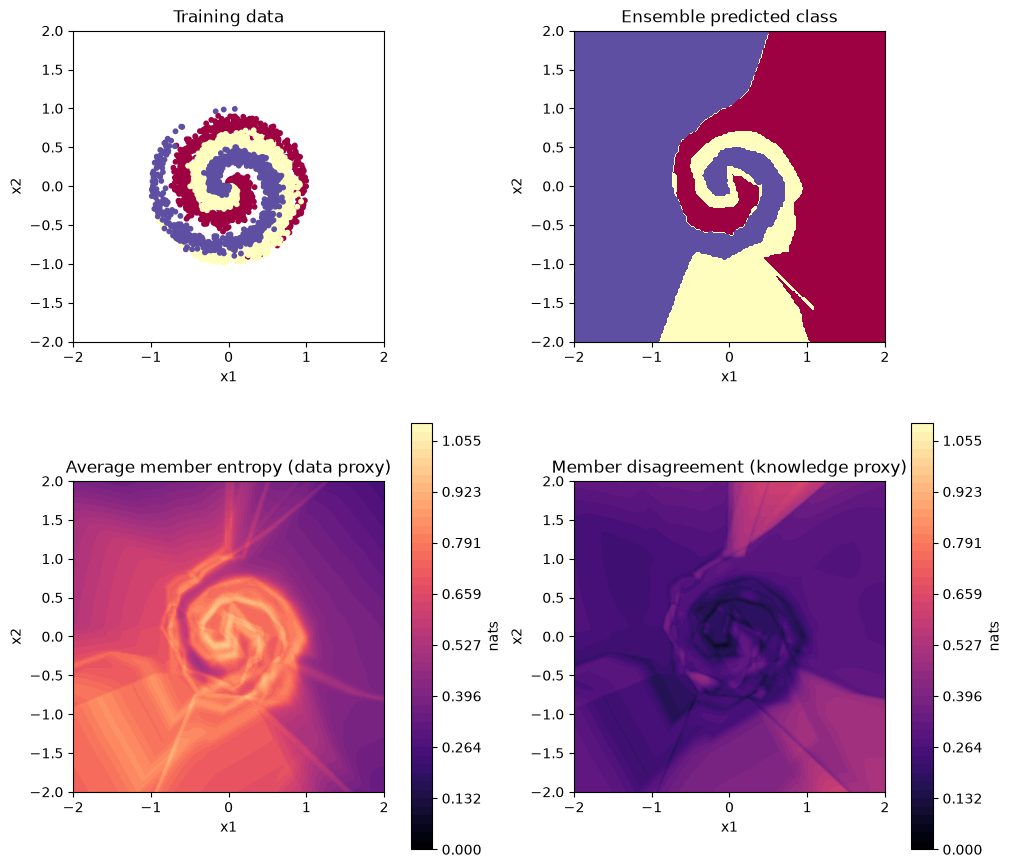

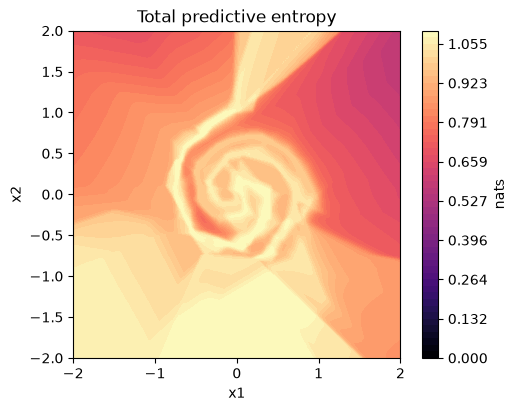

In [18]:
visualize_predictions(X, y, params_mimo, num_nets=M)

### Discussion — MIMO
1. Compare the predictions and uncertainty maps with Part I. Describe observed similarities and differences; neither agreement nor a particular uncertainty pattern is guaranteed.
2. Retrain with $M=1$ and $M=4$, and at least one larger value such as $M=8$, keeping the hidden widths fixed. Compare held-out accuracy/NLL, total entropy and disagreement. How might increasing the number of heads affect the capacity available per prediction? There need not be a monotonic increase in diversity or improvement in calibration.
3. Compare parameter counts and record the update budgets when comparing with deep ensembles. The supplied defaults use 300 updates per independent network in Part I and 2,000 updates of the shared MIMO model here; this is a qualitative demonstration, **not a matched-compute benchmark**. For a controlled timing comparison, also match a clearly stated budget and account for JAX compilation and synchronization.
4. Report your own approximate completion time.

The maps use nats and a common $[0,\log K]$ scale. Average member entropy and disagreement are model-based proxies, not independently verified measurements of irreducible noise or complete epistemic uncertainty. All spiral examples lie in the unit disk; low entropy elsewhere is unjustified confidence unless additional assumptions about the labels are supplied.

1. Inside the unit circle, the pattern of high and low entropy regions is very similar to the results of part 1, though the magnitude of the entropy is higher. Outside the unit circle, there are much larger regions with high entropy - especially the member disagreement is very prevalent which wasn't the case in part 1.
2. Held-out results for different numbers of heads $M$ (hidden widths fixed at 150):

   | $M$ | Held-out accuracy | Held-out NLL | Total entropy (held-out) | Disagreement (held-out) | Total entropy (outside disk) | Disagreement (outside disk) |
   |---|---|---|---|---|---|---|
   | 1 | 0.7880 | 1.3565 | 0.1380 | 0.0000 | 0.0100 | 0.0000 |
   | 4 | 0.9423 | 0.1818 | 0.2401 | 0.0431 | 0.4246 | 0.3819 |
   | 8 | 0.9057 | 0.6438 | 0.9728 | 0.2049 | 0.8760 | 0.3245 |

   Entropies and disagreement ($U_{\text{total}}$ and $U_{\text{knowledge}}$) are in nats and averaged over the 3000 held-out points (inside the unit disk) and over a $200\times200$ grid on $[-2,2]^2$ restricted to points with $\|\boldsymbol{x}\|_2>1$ (outside the disk).

   The accuracy and NLL increases significantly for $M=$ compared to $M=1$ ensemble members, but decreases again for $M=8$ members. Total entropy increases monotonically with more members as well as the disagreement between members. The disagreement between members outside the unit disk is slightly lower for $M=8$ compared to $M=4$ members, though.

3. Comparison with a deep ensemble of $M=4$ networks of the same width (Part I: layers $[2,150,150,3]$), same data, Adam with step size $0.1$, $\lambda=10^{-3}$ and the same held-out set. Training time is the median of three runs of the update loop after one untimed warm-up update (so JAX compilation is excluded), synchronized with `block_until_ready`. Inference time is the time for the 3000 held-out points. The numbers come from a single machine (CPU) and one seed per setting.

   | Model | Updates | Parameters | Training time | Held-out accuracy | Held-out NLL | Inference time |
   |---|---|---|---|---|---|---|
   | Deep ensemble, $M=4$ | 300 per network (1,200 in total) | 94,212 | 3.0 s | 0.9467 | 0.1576 | 2.1 ms |
   | Deep ensemble, $M=4$ | 2,000 per network (8,000 in total) | 94,212 | 20.8 s | 0.9487 | 0.1514 | 2.2 ms |
   | MIMO, $M=4$ | 300 | 25,812 | 2.9 s | 0.9317 | 0.2258 | 1.1 ms |
   | MIMO, $M=4$ | 2,000 | 25,812 | 20.2 s | 0.9423 | 0.1818 | 1.8 ms |

   The MIMO network has about $3.7\times$ fewer parameters than the ensemble ($25{,}812$ vs. $94{,}212$), as only the first and last layer grow with $M$ (a single network has $23{,}553$ parameters). With the same number of updates per model (300 or 2,000) the deep ensemble reaches the better accuracy and NLL, though the margin is small for 2,000 updates. For both budgets the MIMO model needs more updates to catch up and is not better than the ensemble that was trained with fewer updates (ensemble with 300 updates: $0.9467$ / $0.1576$, MIMO with 2,000 updates: $0.9423$ / $0.1818$). The training wall-clock time is about the same for equal update counts, even though the ensemble performs four times as many updates, because one MIMO update is more expensive in this implementation (about $10$ ms vs. $2.5$ ms; the ensemble members are small and the MIMO update additionally draws and applies $M$ permutations). The inference time of MIMO is lower, as only one forward pass is needed instead of four, but the timings of the same MIMO function differed between $1.1$ ms and $1.8$ ms in two measurements, so only the rough ordering is reliable. This is a qualitative comparison and not a matched-compute benchmark.

4. Around 3 hours.

## Image classification
`classification_mnist_pytorch.py` is a **JAX** classifier that uses PyTorch/torchvision only for data loading (the historical filename is retained). Adapt it to either deep ensembles or MIMO. For deep ensembles, initialize and train separate parameter sets and average their class probabilities. For MIMO, use the input/target pairing and repeated-input inference from this notebook.

Install the optional dependencies and follow the command in `README.md`. MNIST requires a download on its first use. Compare a single model with your ensemble using test accuracy and test NLL; do not use the test set for tuning. Any bonus credit is subject to the course's grading policy.

### LLM Usage Report
1. I use Claude Opus 5.5/Sonnet 5.5 to review my implementation, help me find bugs, sometimes fix the code if its minor issues or to suggest more efficient implementations that the one I came up with. Furthermore, I let it review my text answers regarding inconsistencies, flaws or inaccuracies and I improved my answers based on the points mentioned.
2. In my experience LLMs can be "abused" by just letting them do the entire work which leads to a quick completion of the assignment, but one defeats the entire purpose of learning anything. Therefore, I like to do the work myself and let the LLM review my work, discuss solutions and dive deeper into aspects that interest me, to boost my learning and understanding instead. For that purpose they are very well-suited and a great tool that I wouldn't want to miss anymore, but it can be hard at times to resist the urge of just letting it give you the answer straight away if one is stuck/struggling with some task.
3. I think you should allow them because realistically students are going to use them anyways and by now they are definitely here to stay, so I think it's best to find a good way of integrating them into the learning/teaching process that boosts understanding instead of banning them.